# Kenya maize farm risk score: regression models

**Mission.** My mission is to build Africa's capacity to make things, by starting and running technology companies on the continent. This project builds one piece of that: digital infrastructure for farm insurance.

**Problem.** Most smallholder maize farmers in Kenya farm uninsured, so one bad season can wipe them out and lock them out of credit.

**Use case.** The prediction is used by enrolment agents and underwriters at agricultural insurers in Kenya. When a farmer signs up, before planting, the model predicts the field's expected maize yield from what is known at that moment: the field's location and soil, and the inputs the farmer plans to use. The insurer turns the prediction into a low, medium or high risk band to decide cover and price.

**Target.** `yield_kg_ha`: maize grain yield in kilograms per hectare, a continuous number.

**Data.** Aramburu Merlos, F., Tenorio, F. A., Mashingaidze, N., Sananka, A., Aston, S., & Grassini, P. (2024). *Maize management and yield of smallholder farmers in Sub-Saharan Africa between 2016 and 2022* (Version 2) [Dataset]. Zenodo. https://doi.org/10.5281/zenodo.11122388 (CC BY 4.0). One Acre Fund staff measured each field's yield at harvest in two randomly placed 36 m² boxes, and the authors screened the yields for outliers with a Bonferroni outlier test.

In [1]:
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 60)
RANDOM_STATE = 42
TARGET = "yield_kg_ha"

raw = pd.read_csv("One_Acre_Fund_MEL_maize_survey_data_2016-2022.csv")
print(f"{raw.shape[0]:,} rows, {raw.shape[1]} columns")
raw["country"].value_counts()

14,773 rows, 53 columns


country
kenya       7258
tanzania    3710
rwanda      2080
zambia       861
burundi      640
nigeria      115
uganda       109
Name: count, dtype: int64

## Focus on Kenya

Insurers price risk market by market, so the model covers one country. Kenya has the most fields in the survey, and all of them are from the main (long-rains) season, so every row describes the same kind of decision.

In [2]:
kenya = raw[raw["iso"] == "KEN"].reset_index(drop=True)
print(f"{kenya.shape[0]:,} rows, {kenya.shape[1]} columns")
print("Years:", sorted(kenya["year"].unique().tolist()))
print("Seasons:", list(kenya["season"].unique()))
kenya.head()

7,258 rows, 53 columns
Years: [2016, 2017, 2018, 2019, 2020]
Seasons: ['first season']


,year,country,iso,season,cz,lon,lat,strat,avg_season_gdd,avg_season_ai,avg_season_tavg,season_prec,season_prec_1,season_prec_2,season_prec_3,elev,twi,soil_rzpawhc,soil_clay,soil_pH,soil_orgC,soil_ECEC,plant_date,harvest_date,plant_date_dev,plant_doy,pl_m2,row_spacing,hybrid,hyb_type,hyb_mat,hyb_yor,hyb_tol_mln,hyb_tol_msv,hyb_tol_gls,hyb_tol_nclb,hyb_tol_rust,hyb_tol_ear_rot,N_kg_ha,P_kg_ha,K_kg_ha,compost,comp_kg_ha,manure,fert_in_hole,lime_kg_ha,weeding,pesticide,disease,pest,striga,water_excess,yield_kg_ha
0,2016,kenya,KEN,first season,7701,34.067,0.227,01_KEN7701S1,2509.099854,0.998492,21.275661,677.039708,228.759519,365.227443,83.052746,1280,8.322142,120.0,34.0,6.3,11.182494,13.879732,2016-04-13,NaN,22.0,104.0,NaN,70.666656,True,NaN,2.0,2004.0,False,False,False,False,False,False,51.892050,24.71050,0.0,False,0.0,NaN,True,0.0,NaN,NaN,False,False,NaN,False,1462.951369
1,2017,kenya,KEN,first season,7701,34.100,0.238,01_KEN7701S1,2552.900146,1.038017,21.507408,760.532583,154.624451,464.134379,141.773752,1288,10.117007,120.0,38.0,5.9,12.463738,12.463738,2017-03-31,2017-07-14,8.0,90.0,2.736283,68.666664,True,NaN,2.0,2004.0,False,False,False,False,False,False,51.892050,24.71050,0.0,False,0.0,NaN,True,0.0,False,True,False,True,NaN,False,2817.771269
2,2019,kenya,KEN,first season,7701,34.082,0.247,01_KEN7701S1,2580.099854,1.008526,21.651323,724.153837,181.676820,359.354439,183.122578,1243,7.909871,120.0,33.0,6.2,10.023176,10.023176,2019-04-15,2019-08-05,23.0,105.0,4.541739,72.666664,True,NaN,2.0,2004.0,False,False,False,False,False,False,27.873444,13.83788,0.0,False,0.0,NaN,True,0.0,False,False,False,True,NaN,False,0.000000
3,2020,kenya,KEN,first season,7701,34.098,0.232,01_KEN7701S1,2562.800049,1.018445,21.559790,998.342599,379.451999,428.776234,190.114366,1271,8.969049,120.0,32.0,6.0,10.023176,10.023176,2020-03-28,2020-07-16,6.0,88.0,3.986111,NaN,True,3_way_hyb,1.0,2003.0,False,False,True,False,False,True,44.478900,49.42100,0.0,True,NaN,True,False,0.0,True,False,False,True,True,False,4788.722787
4,2020,kenya,KEN,first season,7701,34.094,0.272,01_KEN7701S1,2612.800049,1.023641,21.824339,998.342599,379.451999,428.776234,190.114366,1226,6.008638,120.0,33.0,5.9,12.463738,11.182494,2020-02-05,2020-08-04,-46.0,36.0,2.277778,NaN,True,NaN,2.0,2004.0,False,False,False,False,False,False,51.892050,24.71050,0.0,False,NaN,NaN,False,0.0,False,NaN,False,False,True,False,2193.982268


In [3]:
features_all = kenya.drop(columns=TARGET)
numeric_columns = features_all.select_dtypes("number").columns
categorical_columns = features_all.columns.difference(numeric_columns)
print(f"{len(kenya):,} rows and {features_all.shape[1]} feature columns: "
      f"{len(numeric_columns)} numeric, {len(categorical_columns)} categorical (text or yes/no)")
print("Categorical columns:", list(categorical_columns))
kenya[TARGET].describe().round(1)

7,258 rows and 52 feature columns: 29 numeric, 23 categorical (text or yes/no)
Categorical columns: ['compost', 'country', 'disease', 'fert_in_hole', 'harvest_date', 'hyb_tol_ear_rot', 'hyb_tol_gls', 'hyb_tol_mln', 'hyb_tol_msv', 'hyb_tol_nclb', 'hyb_tol_rust', 'hyb_type', 'hybrid', 'iso', 'manure', 'pest', 'pesticide', 'plant_date', 'season', 'strat', 'striga', 'water_excess', 'weeding']


count    7258.0
mean     3019.7
std      1707.2
min         0.0
25%      1806.8
50%      2764.6
75%      3973.6
max      9903.5
Name: yield_kg_ha, dtype: float64

## Explore the data

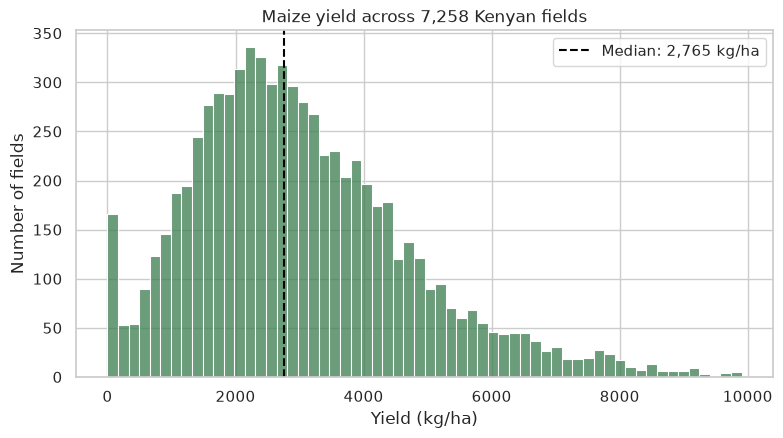

Fields with zero yield: 144
Fields under 1,000 kg/ha: 8.9%


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

median_yield = kenya[TARGET].median()
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(kenya[TARGET], bins=60, color="#3b7d4f", ax=ax)
ax.axvline(median_yield, color="black", linestyle="--", label=f"Median: {median_yield:,.0f} kg/ha")
ax.set(title=f"Maize yield across {len(kenya):,} Kenyan fields", xlabel="Yield (kg/ha)", ylabel="Number of fields")
ax.legend()
plt.show()

print(f"Fields with zero yield: {(kenya[TARGET] == 0).sum()}")
print(f"Fields under 1,000 kg/ha: {(kenya[TARGET] < 1000).mean():.1%}")

**What it shows.** Yield is skewed to the right: most fields harvest between 1,500 and 4,500 kg/ha (median 2,765), a long tail reaches almost 10,000 kg/ha, and 144 fields recorded zero. **What I decided.** I keep the zero-yield fields, because a crop failure is exactly the event an insurer has to price and the dataset's authors already screened the yields for statistical outliers. Because MSE squares errors, these extremes weigh heavily in the loss, so I also report RMSE in kg/ha to keep the errors readable.

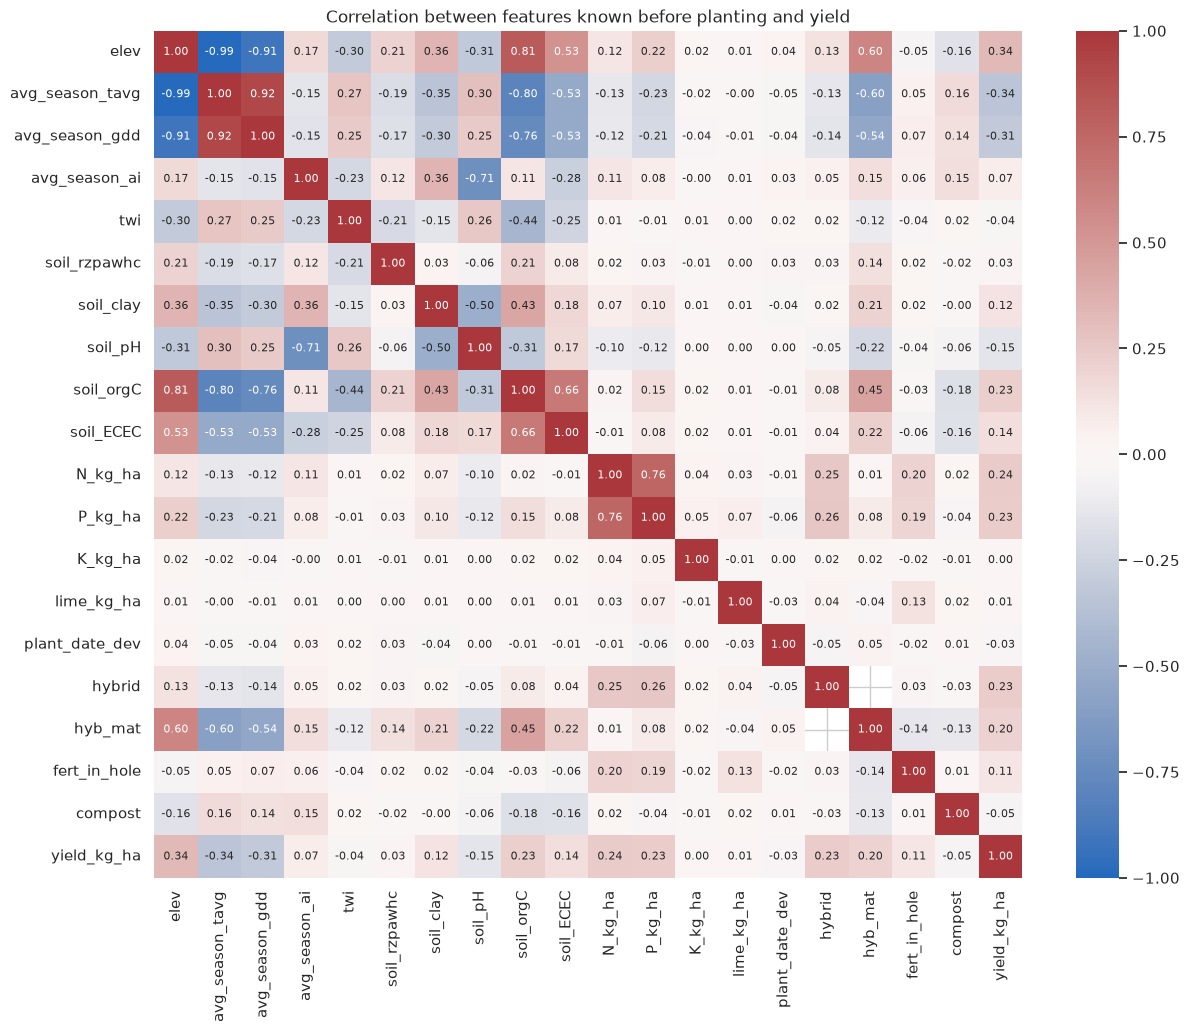

In [5]:
pre_planting = [
    "elev", "avg_season_tavg", "avg_season_gdd", "avg_season_ai", "twi", "soil_rzpawhc",
    "soil_clay", "soil_pH", "soil_orgC", "soil_ECEC", "N_kg_ha", "P_kg_ha", "K_kg_ha",
    "lime_kg_ha", "plant_date_dev", "hybrid", "hyb_mat", "fert_in_hole", "compost",
]
eda = kenya[pre_planting + [TARGET]].astype(float)

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(eda.corr(), annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1,
            annot_kws={"size": 8}, ax=ax)
ax.set_title("Correlation between features known before planting and yield")
plt.show()

**What it shows.** Elevation, average season temperature and growing degree days are almost the same measurement (r = −0.99 and −0.91 with elevation), and yield's strongest links are only moderate: elevation +0.34, nitrogen +0.24, and phosphorus, hybrid seed and soil organic carbon +0.23 each. **What I decided.** I keep only elevation from that trio, because an agent can read it from a phone's GPS, and because no link is strong I also test non-linear models. Nitrogen and phosphorus overlap (0.76), so I test later whether both are needed (the blank hybrid and maturity cells appear because maturity is only recorded for hybrids).

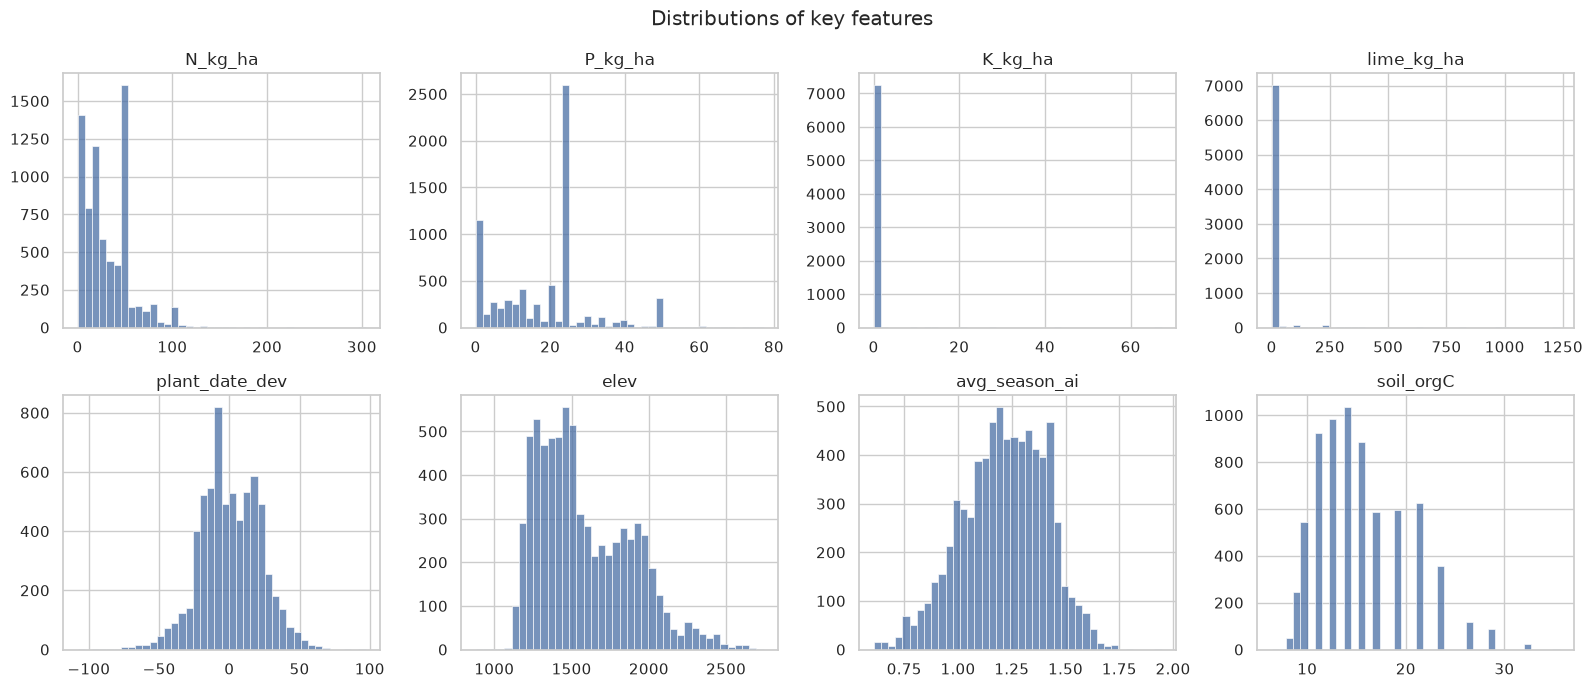

N_kg_ha: zero in 10.9% of fields
P_kg_ha: zero in 15.4% of fields
K_kg_ha: zero in 99.7% of fields
lime_kg_ha: zero in 96.1% of fields


In [6]:
to_plot = ["N_kg_ha", "P_kg_ha", "K_kg_ha", "lime_kg_ha", "plant_date_dev", "elev", "avg_season_ai", "soil_orgC"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, column in zip(axes.flat, to_plot):
    sns.histplot(kenya[column].dropna(), bins=40, color="#4a6fa5", ax=ax)
    ax.set(title=column, xlabel="", ylabel="")
fig.suptitle("Distributions of key features")
plt.tight_layout()
plt.show()

for column in ["N_kg_ha", "P_kg_ha", "K_kg_ha", "lime_kg_ha"]:
    print(f"{column}: zero in {(kenya[column] == 0).mean():.1%} of fields")

**What it shows.** Potassium is zero on 99.7% of fields and lime on 96.1%, while nitrogen and phosphorus pile up at zero and at about 50 and 25 kg/ha, which suggests many farmers apply the same standard rate. Planting dates centre on the local average, mostly within about three weeks of it, and elevation runs from about 900 to 2,700 m. **What I decided.** I drop potassium and lime because they carry almost no information, and I use these observed ranges to set the input limits in the API.

## Feature engineering: columns we drop and why

The model may only use what an insurer knows when the farmer enrols, before planting. Each dropped column falls into one of these groups. The evidence for each group is printed below.

| Group | Columns | Why |
|---|---|---|
| Only known once the season is under way | `season_prec`, `season_prec_1`, `season_prec_2`, `season_prec_3`, `harvest_date`, `pl_m2`, `row_spacing`, `weeding`, `pesticide`, `disease`, `pest`, `striga`, `water_excess` | Rainfall during the season, plant counts and crop damage are measured after enrolment. Using them would let the model see the future. |
| Identifiers, single values or raw forms | `country`, `iso`, `season`, `strat`, `year`, `cz`, `lat`, `lon`, `plant_date`, `plant_doy` | Country, ISO code and season have one value in Kenya. `strat` is a survey label. `year` only covers 2016 to 2020, so future enrolment years fall outside it. An agent cannot know the climate-zone code `cz`, and raw coordinates are not something an agent types; elevation, aridity and the soil values carry the location's effect. Calendar planting dates are tied to one year, so `plant_date_dev` (days earlier or later than the local average) replaces them. |
| Mostly empty | `manure`, `hyb_type`, `hyb_yor`, `hyb_tol_mln`, `hyb_tol_msv`, `hyb_tol_gls`, `hyb_tol_nclb`, `hyb_tol_rust`, `hyb_tol_ear_rot`, `comp_kg_ha` | More than 25% missing. |
| Almost always zero | `K_kg_ha`, `lime_kg_ha` | No variation means no information. |
| Duplicates of elevation | `avg_season_tavg`, `avg_season_gdd` | The heatmap shows correlations of −0.99 and −0.91 with elevation. Elevation stays because an agent can read it from a phone's GPS. |
| Combined into `seed_type` | `hybrid`, `hyb_mat` | Replaced by one categorical feature, built below. |

In [7]:
DROPPED = {
    "only known once the season is under way": [
        "season_prec", "season_prec_1", "season_prec_2", "season_prec_3", "harvest_date", "pl_m2",
        "row_spacing", "weeding", "pesticide", "disease", "pest", "striga", "water_excess"],
    "identifiers, single values or raw forms": [
        "country", "iso", "season", "strat", "year", "cz", "lat", "lon", "plant_date", "plant_doy"],
    "mostly empty": [
        "manure", "hyb_type", "hyb_yor", "hyb_tol_mln", "hyb_tol_msv", "hyb_tol_gls",
        "hyb_tol_nclb", "hyb_tol_rust", "hyb_tol_ear_rot", "comp_kg_ha"],
    "almost always zero": ["K_kg_ha", "lime_kg_ha"],
    "duplicates of elevation": ["avg_season_tavg", "avg_season_gdd"],
    "combined into seed_type": ["hybrid", "hyb_mat"],
}
KEPT = ["elev", "avg_season_ai", "twi", "soil_rzpawhc", "soil_clay", "soil_pH", "soil_orgC",
        "soil_ECEC", "N_kg_ha", "P_kg_ha", "plant_date_dev", "fert_in_hole", "compost"]

dropped_columns = [column for group in DROPPED.values() for column in group]
assert sorted(dropped_columns + KEPT + [TARGET]) == sorted(kenya.columns), "every column must be kept or dropped"

evidence = pd.DataFrame({
    "group": {column: group for group, columns in DROPPED.items() for column in columns},
    "missing %": kenya[dropped_columns].isna().mean().mul(100).round(1),
    "distinct values": kenya[dropped_columns].nunique(),
})
in_season_numeric = ["season_prec", "season_prec_1", "season_prec_2", "season_prec_3", "pl_m2"]
evidence["corr with yield"] = kenya[in_season_numeric].corrwith(kenya[TARGET]).round(2)
evidence

,group,missing %,distinct values,corr with yield
season_prec,only known once the season is under way,0.0,2331,0.18
season_prec_1,only known once the season is under way,0.0,2321,0.06
season_prec_2,only known once the season is under way,0.0,2281,0.05
season_prec_3,only known once the season is under way,0.0,2296,0.27
harvest_date,only known once the season is under way,20.8,648,NaN
pl_m2,only known once the season is under way,32.8,2978,0.30
row_spacing,only known once the season is under way,56.1,359,NaN
weeding,only known once the season is under way,15.7,2,NaN
pesticide,only known once the season is under way,51.3,2,NaN
disease,only known once the season is under way,0.0,2,NaN


The in-season columns do relate to yield (whole-season rainfall has r = 0.18), but none of them exist when the farmer enrols, so keeping them would make the model look better on paper than it can be in use. After these drops, 13 candidate features remain, and `seed_type` is built next.

### Engineer `seed_type`

`hybrid` says whether the farmer planted a commercial hybrid, and `hyb_mat` gives the hybrid's maturity on a 0.5 to 3 scale. The dataset describes maturity as early, medium or late, so whole numbers 1, 2 and 3 map to those classes. The half-steps are not defined, so the yields decide where they go.

In [8]:
hybrids = kenya[kenya["hybrid"] == True]
hybrids.groupby("hyb_mat", dropna=False)[TARGET].agg(["count", "median"]).round(0)

,count,median
hyb_mat,,
0.5,13,1555.0
1.0,1155,2735.0
1.5,134,2809.0
2.0,834,2652.0
2.5,849,2792.0
3.0,2442,3492.0
NaN,945,2228.0


Maturity 3 (late) clearly stands apart, at a median of 3,492 kg/ha. The half-steps 1.5 and 2.5 yield like early and medium hybrids (2,809 and 2,792 kg/ha), not like late ones, so each half-step joins the class below it, and the 13 fields at 0.5 join the early class.

In [9]:
SEED_TYPES = ["local_or_opv", "hybrid_early", "hybrid_medium", "hybrid_late", "hybrid_unknown_maturity"]


def seed_type(is_hybrid, maturity):
    if not is_hybrid:
        return "local_or_opv"
    if pd.isna(maturity):
        return "hybrid_unknown_maturity"
    if maturity <= 1.5:
        return "hybrid_early"
    if maturity <= 2.5:
        return "hybrid_medium"
    return "hybrid_late"


data = kenya[KEPT + [TARGET]].copy()
data["seed_type"] = [seed_type(h, m) for h, m in zip(kenya["hybrid"], kenya["hyb_mat"])]
CANDIDATES = KEPT + ["seed_type"]

data.groupby("seed_type")[TARGET].agg(["count", "median"]).reindex(SEED_TYPES).round(0)

,count,median
seed_type,,
local_or_opv,886,1781.0
hybrid_early,1302,2736.0
hybrid_medium,1683,2703.0
hybrid_late,2442,3492.0
hybrid_unknown_maturity,945,2228.0


Seed type matters: late-maturing hybrids yield a median of 3,492 kg/ha, about double the 1,781 kg/ha from local or open-pollinated seed. Hybrids whose maturity was not recorded sit in between, so they keep their own category instead of being guessed.

## Convert categorical columns to numeric

Two kinds of categorical columns remain:

- **Yes/no columns** (`fert_in_hole`, `compost`) become 1 and 0. Blank `compost` values stay blank and are filled later.
- **`seed_type`** has five text values. One-hot encoding turns it into four 0/1 columns, with `local_or_opv` as the baseline that the others are compared against.

In [10]:
for column in ["fert_in_hole", "compost"]:
    before = data[column].map(repr).value_counts(dropna=False).to_dict()
    data[column] = data[column].map({True: 1, False: 0})
    after = data[column].value_counts(dropna=False).to_dict()
    print(f"{column}\n  before: {before}\n  after:  {after}")

fert_in_hole
  before: {'False': 4592, 'True': 2666}
  after:  {0: 4592, 1: 2666}
compost
  before: {'False': 4684, 'True': 1361, 'nan': 1213}
  after:  {0.0: 4684, 1.0: 1361, nan: 1213}


In [11]:
from sklearn.preprocessing import OneHotEncoder

seed_encoder = OneHotEncoder(categories=[SEED_TYPES], drop="first", sparse_output=False)
seed_onehot = pd.DataFrame(seed_encoder.fit_transform(data[["seed_type"]]),
                           columns=seed_encoder.get_feature_names_out(), index=data.index).astype(int)
pd.concat([data["seed_type"], seed_onehot], axis=1).drop_duplicates().set_index("seed_type").reindex(SEED_TYPES)

,seed_type_hybrid_early,seed_type_hybrid_medium,seed_type_hybrid_late,seed_type_hybrid_unknown_maturity
seed_type,,,,
local_or_opv,0,0,0,0
hybrid_early,1,0,0,0
hybrid_medium,0,1,0,0
hybrid_late,0,0,1,0
hybrid_unknown_maturity,0,0,0,1


The five categories are fixed in advance, so the encoder learns nothing from the data and encoding before the split leaks nothing. The same encoder sits inside the saved pipeline, so the API can send `seed_type` as text and get the same columns.

## Split into train and test sets, then standardize

80% of the fields train the models and 20% are held back as the test set for every model. The scaler, and the median used to fill blank values, are fitted on the training set only and then applied to the test set.

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

X = data[CANDIDATES]
y = data[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"Train: {len(X_train):,} fields | Test: {len(X_test):,} fields")


def build_preprocessor(numeric_features):
    encode = ColumnTransformer([
        ("numeric", SimpleImputer(strategy="median"), numeric_features),
        ("seed_type", OneHotEncoder(categories=[SEED_TYPES], drop="first"), ["seed_type"]),
    ])
    return Pipeline([("encode", encode), ("scale", StandardScaler())])


numeric_candidates = [column for column in CANDIDATES if column != "seed_type"]
preprocessor = build_preprocessor(numeric_candidates).fit(X_train)
encoded_names = preprocessor.named_steps["encode"].get_feature_names_out()
train_scaled = pd.DataFrame(preprocessor.transform(X_train), columns=encoded_names)
test_scaled = pd.DataFrame(preprocessor.transform(X_test), columns=encoded_names)

pd.DataFrame({
    "train mean": train_scaled.mean(), "train std": train_scaled.std(ddof=0),
    "test mean": test_scaled.mean(), "test std": test_scaled.std(ddof=0),
}).round(3)

Train: 5,806 fields | Test: 1,452 fields


,train mean,train std,test mean,test std
numeric__elev,-0.0,1.0,0.014,1.001
numeric__avg_season_ai,0.0,1.0,0.012,0.993
numeric__twi,0.0,1.0,-0.019,0.970
numeric__soil_rzpawhc,0.0,1.0,0.048,0.966
numeric__soil_clay,0.0,1.0,0.027,0.997
numeric__soil_pH,0.0,1.0,-0.020,1.014
numeric__soil_orgC,0.0,1.0,0.008,0.992
numeric__soil_ECEC,-0.0,1.0,0.026,1.040
numeric__N_kg_ha,0.0,1.0,-0.005,0.984
numeric__P_kg_ha,-0.0,1.0,0.003,1.000


After scaling, every training column has a mean of 0 and a standard deviation of 1. The test columns are close but not exact, which shows that the scaler learned only from the training set.

## Feature engineering, continued: which features matter most

Correlation only measures straight-line links, so it can miss features that matter in other ways. Two tests on the **training set only** measure each candidate's real contribution. The test set stays untouched.

1. **Permutation importance.** A random forest trains on 75% of the training set. Shuffling one feature at a time on the other 25% shows how much the error grows without that feature.
2. **Drop-one cross-validation.** For each candidate, 5-fold cross-validation (repeated 3 times) on the training set measures the error without that feature. A feature whose removal changes the error by less than 0.1% adds nothing, so it is dropped, which also shortens the app's form.

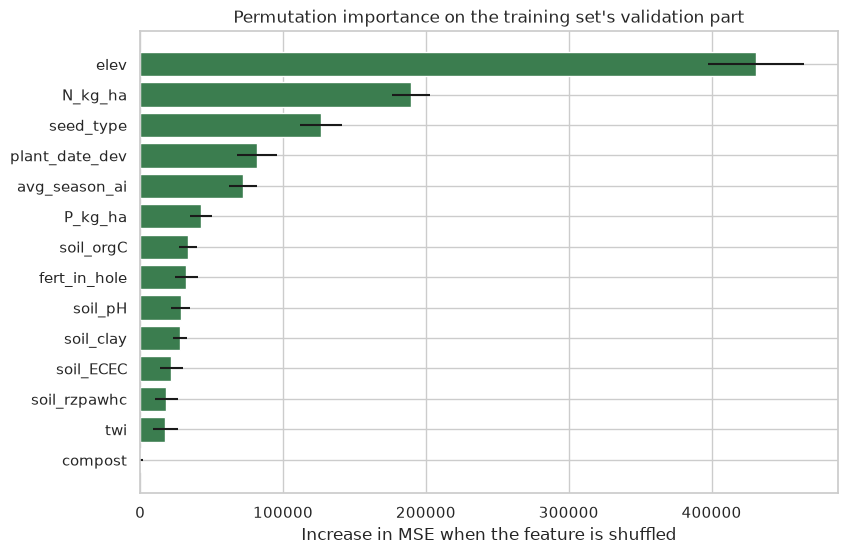

In [13]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance

X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=RANDOM_STATE)
probe = Pipeline([
    ("prep", build_preprocessor(numeric_candidates)),
    ("model", RandomForestRegressor(n_estimators=300, min_samples_leaf=5, max_features=0.5,
                                    random_state=RANDOM_STATE, n_jobs=-1)),
]).fit(X_fit, y_fit)
permutation = permutation_importance(probe, X_val, y_val, scoring="neg_mean_squared_error",
                                     n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.DataFrame({"MSE increase": permutation.importances_mean,
                           "spread": permutation.importances_std}, index=CANDIDATES).sort_values("MSE increase")

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(importance.index, importance["MSE increase"], xerr=importance["spread"], color="#3b7d4f")
ax.set(title="Permutation importance on the training set's validation part",
       xlabel="Increase in MSE when the feature is shuffled")
plt.show()

**What it shows.** Elevation matters most by far: shuffling it raises the error more than twice as much as any other feature, followed by nitrogen, seed type, planting date and aridity, while compost adds nothing. **What I decided.** Phosphorus ranks sixth here even though it overlaps with nitrogen, so the next test checks whether the model actually needs it, along with the weakest features.

In [14]:
from sklearn.model_selection import RepeatedKFold, cross_val_score

repeated_cv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)


def cv_mse(features):
    numeric = [column for column in features if column != "seed_type"]
    pipe = Pipeline([
        ("prep", build_preprocessor(numeric)),
        ("model", RandomForestRegressor(n_estimators=150, min_samples_leaf=5, max_features=0.5,
                                        random_state=RANDOM_STATE, n_jobs=-1)),
    ])
    scores = -cross_val_score(pipe, X_train[features], y_train, cv=repeated_cv, scoring="neg_mean_squared_error")
    return scores.mean(), scores.std() / np.sqrt(len(scores))


baseline_mse, baseline_se = cv_mse(CANDIDATES)
drop_one = pd.DataFrame(
    {column: cv_mse([c for c in CANDIDATES if c != column])[0] for column in numeric_candidates},
    index=["CV MSE without it"]).T
drop_one["change vs all candidates"] = drop_one["CV MSE without it"] - baseline_mse
drop_one["change %"] = drop_one["change vs all candidates"] / baseline_mse * 100
print(f"All {len(CANDIDATES)} candidates: CV MSE {baseline_mse:,.0f} (standard error {baseline_se:,.0f})")
drop_one.sort_values("change vs all candidates").style.format(
    {"CV MSE without it": "{:,.0f}", "change vs all candidates": "{:+,.0f}", "change %": "{:+.2f}%"})

All 14 candidates: CV MSE 2,176,187 (standard error 23,550)


,CV MSE without it,change vs all candidates,change %
twi,"2,175,608",-579,-0.03%
P_kg_ha,"2,177,438","+1,251",+0.06%
compost,"2,177,600","+1,413",+0.06%
soil_pH,"2,183,643","+7,456",+0.34%
soil_ECEC,"2,186,149","+9,962",+0.46%
soil_clay,"2,186,537","+10,350",+0.48%
soil_orgC,"2,187,005","+10,817",+0.50%
soil_rzpawhc,"2,187,719","+11,532",+0.53%
fert_in_hole,"2,190,311","+14,124",+0.65%
N_kg_ha,"2,197,554","+21,367",+0.98%


In [15]:
DROPPED_BY_TEST = drop_one.index[drop_one["change %"] < 0.1].tolist()
FEATURES = [column for column in CANDIDATES if column not in DROPPED_BY_TEST]
final_mse, final_se = cv_mse(FEATURES)

print("Dropped after testing:", DROPPED_BY_TEST)
print(f"Final features ({len(FEATURES)}):", FEATURES)
print(f"CV MSE with all candidates: {baseline_mse:,.0f} (standard error {baseline_se:,.0f})")
print(f"CV MSE with final features: {final_mse:,.0f} (standard error {final_se:,.0f})")

Dropped after testing: ['twi', 'P_kg_ha', 'compost']
Final features (11): ['elev', 'avg_season_ai', 'soil_rzpawhc', 'soil_clay', 'soil_pH', 'soil_orgC', 'soil_ECEC', 'N_kg_ha', 'plant_date_dev', 'fert_in_hole', 'seed_type']
CV MSE with all candidates: 2,176,187 (standard error 23,550)
CV MSE with final features: 2,172,814 (standard error 24,733)


Removing wetness index, phosphorus or compost changes the cross-validated error by less than 0.1%, so they are dropped: nitrogen already carries phosphorus's information (r = 0.76), and the other two add nothing. Most changes in the table are smaller than one standard error (about 23,500), and the final 11 features give a CV MSE of 2,172,814 against 2,176,187 with all 14, so the smaller form for the agent costs no accuracy. The features that matter most for yield are elevation, planting date, aridity, nitrogen and fertilizer placement (the largest increases when removed), with seed type close behind in the permutation test.

## Train and compare four models

Every model is a pipeline: the same preprocessing (fill blanks, one-hot encode `seed_type`, standardize) followed by the model. Each pipeline is fitted on the training set and scored on the same test set with mean squared error (MSE).

In [16]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

NUMERIC_FEATURES = [column for column in FEATURES if column != "seed_type"]
X_train, X_test = X_train[FEATURES], X_test[FEATURES]


def make_model(estimator):
    return Pipeline([("prep", build_preprocessor(NUMERIC_FEATURES)), ("model", estimator)])


models, results = {}, {}


def evaluate(name, pipe):
    models[name] = pipe
    results[name] = {
        "Train MSE": mean_squared_error(y_train, pipe.predict(X_train)),
        "Test MSE": mean_squared_error(y_test, pipe.predict(X_test)),
        "Test RMSE (kg/ha)": mean_squared_error(y_test, pipe.predict(X_test)) ** 0.5,
        "Test R²": r2_score(y_test, pipe.predict(X_test)),
    }
    print(f"{name}: train MSE {results[name]['Train MSE']:,.0f} | test MSE {results[name]['Test MSE']:,.0f}")

### Linear regression, closed form

`LinearRegression` solves for the best straight-line weights in one exact calculation.

In [17]:
linear = make_model(LinearRegression()).fit(X_train, y_train)
evaluate("Linear regression (closed form)", linear)

coefficients = pd.Series(linear.named_steps["model"].coef_,
                         index=linear.named_steps["prep"].named_steps["encode"].get_feature_names_out())
coefficients.sort_values().round(0).to_frame("kg/ha per 1 standard deviation")

Linear regression (closed form): train MSE 2,316,768 | test MSE 2,433,879


,kg/ha per 1 standard deviation
numeric__soil_orgC,-229.0
numeric__soil_pH,-144.0
numeric__avg_season_ai,-80.0
numeric__plant_date_dev,-47.0
numeric__soil_rzpawhc,-47.0
numeric__soil_clay,-27.0
numeric__soil_ECEC,55.0
numeric__fert_in_hole,140.0
seed_type__seed_type_hybrid_unknown_maturity,184.0
numeric__N_kg_ha,206.0


Holding everything else fixed, one standard deviation more elevation adds about 620 kg/ha, a late hybrid adds about 470 kg/ha over local seed, and one standard deviation more nitrogen adds about 210 kg/ha. Soil organic carbon gets a negative weight even though its own correlation with yield is positive, because it overlaps with elevation (r = 0.81) and the model splits their shared effect. Straight-line models struggle with overlapping features like these, which is one reason to also try trees.

### Linear regression by gradient descent: tuning `SGDRegressor`

`SGDRegressor` learns the same straight-line model by taking small steps downhill on the error, a few rows at a time. Three settings were tuned with 5-fold cross-validation on the training set:

- **Learning rate** (`eta0`): the size of each step, kept constant.
- **Regularization strength** (`alpha`): a penalty on large weights. 0 means no penalty.
- **Number of epochs** (`max_iter`): full passes over the training data. `tol=None` makes it run exactly that many.

In [18]:
from sklearn.linear_model import SGDRegressor
from sklearn.model_selection import GridSearchCV, KFold

kfold = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
sgd_grid = {
    "model__eta0": [1e-6, 1e-5, 1e-4, 1e-3, 1e-2],
    "model__alpha": [0, 1e-4, 1e-3, 1e-2, 1e-1, 1],
    "model__max_iter": [5, 10, 20, 50, 100, 200],
}
sgd_search = GridSearchCV(
    make_model(SGDRegressor(learning_rate="constant", tol=None, random_state=RANDOM_STATE)),
    sgd_grid, cv=kfold, scoring="neg_mean_squared_error", n_jobs=-1,
).fit(X_train, y_train)

sgd_best = {name.replace("model__", ""): value for name, value in sgd_search.best_params_.items()}
print("Best settings:", sgd_best)
print(f"Best CV MSE: {-sgd_search.best_score_:,.0f}")

Best settings: {'alpha': 0, 'eta0': 0.0001, 'max_iter': 50}
Best CV MSE: 2,328,543


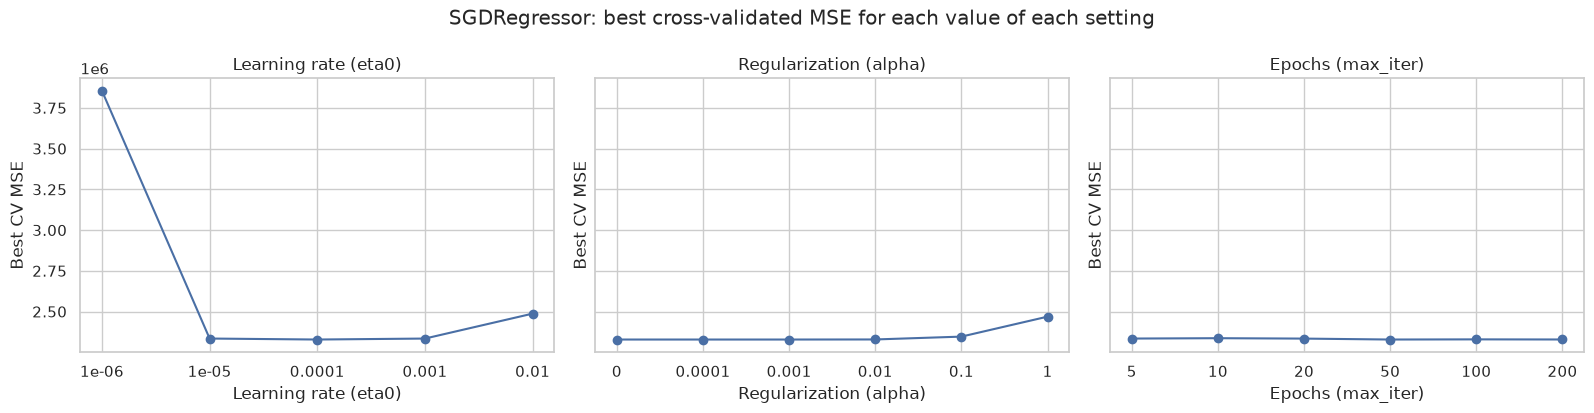

{1e-06: '3,855,004', 1e-05: '2,334,621', 0.0001: '2,328,543', 0.001: '2,334,525', 0.01: '2,487,584'}
{0.0: '2,328,543', 0.0001: '2,328,544', 0.001: '2,328,555', 0.01: '2,328,975', 0.1: '2,346,448', 1.0: '2,468,973'}
{5: '2,334,525', 10: '2,336,726', 20: '2,334,284', 50: '2,328,543', 100: '2,329,528', 200: '2,328,812'}


In [19]:
cv_table = pd.DataFrame(sgd_search.cv_results_)
cv_table["CV MSE"] = -cv_table["mean_test_score"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
labels = {"model__eta0": "Learning rate (eta0)", "model__alpha": "Regularization (alpha)",
          "model__max_iter": "Epochs (max_iter)"}
for ax, (param, label) in zip(axes, labels.items()):
    best_per_value = cv_table.groupby(f"param_{param}")["CV MSE"].min()
    ax.plot(range(len(best_per_value)), best_per_value.values, marker="o", color="#4a6fa5")
    ax.set_xticks(range(len(best_per_value)), [f"{v:g}" for v in best_per_value.index])
    ax.set(title=label, xlabel=label, ylabel="Best CV MSE")
fig.suptitle("SGDRegressor: best cross-validated MSE for each value of each setting")
plt.tight_layout()
plt.show()

for param in labels:
    print(cv_table.groupby(f"param_{param}")["CV MSE"].min().map("{:,.0f}".format).to_dict())

**What it shows.** The learning rate matters most: 0.000001 is too small to get anywhere in the allowed epochs (CV MSE 3.86 million), 0.01 overshoots (2.49 million), and 0.0001 is best (2.33 million). Regularization makes no difference up to 0.01 and hurts from 0.1, and the number of epochs barely matters once the learning rate is right (every value from 5 to 200 lands within 0.4%). **What I decided.** I use a learning rate of 0.0001, no regularization (a model with only 14 weights has little room to overfit) and 50 epochs, the best combination.

In [20]:
evaluate("Linear regression (SGD)", sgd_search.best_estimator_)

Linear regression (SGD): train MSE 2,316,869 | test MSE 2,433,627
